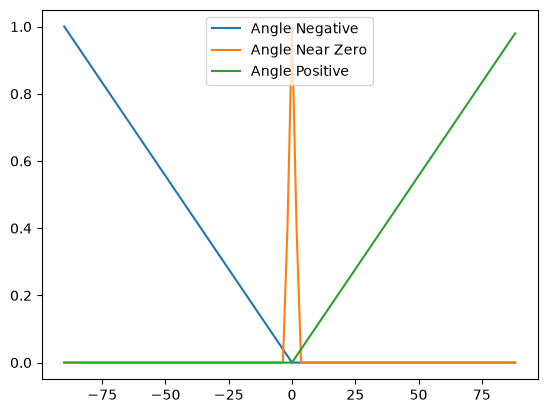

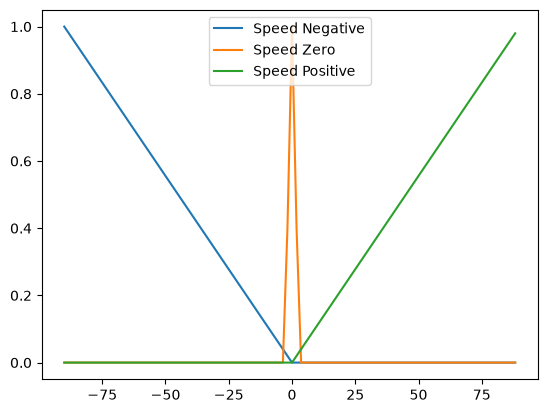

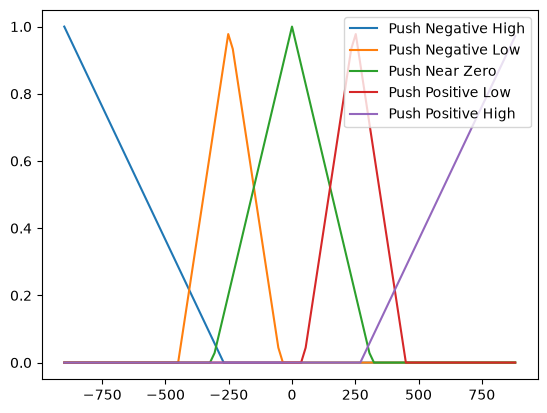

In [1]:
#
# fuzzy_speed_control.py
#

import math
import arslabrobotics as ar

class InvertedPendulumFuzzyController:

    def __init__(self):
        # fuzzy sets for angle
        angle_neg = ar.fuzzy.Down("Angle Negative", -90, 0)
        angle_zero = ar.fuzzy.Triangle("Angle Near Zero", -3, 3)
        angle_pos = ar.fuzzy.Up("Angle Positive", 0, 90)
        ar.fuzzy.plot_fuzzysets([angle_neg, angle_zero, angle_pos])

        # fuzzy sets for speed
        speed_neg = ar.fuzzy.Down("Speed Negative", -90, 0)
        speed_zero = ar.fuzzy.Triangle("Speed Zero", -3, 3)
        speed_pos = ar.fuzzy.Up("Speed Positive", 0, 90)
        ar.fuzzy.plot_fuzzysets([speed_neg, speed_zero, speed_pos])

        # fuzzy sets for push
        PUSH_MAX = 900
        push_neg_high = ar.fuzzy.Down("Push Negative High", -PUSH_MAX, -PUSH_MAX * 0.3)
        push_neg_low = ar.fuzzy.Triangle("Push Negative Low", -PUSH_MAX * 0.5, -PUSH_MAX * 0.05)
        push_zero = ar.fuzzy.Triangle("Push Near Zero", -PUSH_MAX * 0.35, PUSH_MAX * 0.35)
        push_pos_low = ar.fuzzy.Triangle("Push Positive Low", PUSH_MAX * 0.05, PUSH_MAX * 0.5)
        push_pos_high = ar.fuzzy.Up("Push Positive High", PUSH_MAX * 0.3, PUSH_MAX)
        ar.fuzzy.plot_fuzzysets([push_neg_high, push_neg_low, push_zero, push_pos_low, push_pos_high])

        self.angle = ar.fuzzy.Variable()
        self.speed = ar.fuzzy.Variable()
        self.push = ar.fuzzy.Variable()

        r11 = (self.angle(angle_neg) & self.speed(speed_neg)) >> self.push(push_pos_high)
        r12 = (self.angle(angle_neg) & self.speed(speed_zero)) >> self.push(push_pos_low)
        r13 = (self.angle(angle_neg) & self.speed(speed_pos)) >> self.push(push_zero)

        r21 = (self.angle(angle_zero) & self.speed(speed_neg)) >> self.push(push_pos_low)
        r22 = (self.angle(angle_zero) & self.speed(speed_zero)) >> self.push(push_zero)
        r23 = (self.angle(angle_zero) & self.speed(speed_pos)) >> self.push(push_neg_low)

        r31 = (self.angle(angle_pos) & self.speed(speed_neg)) >> self.push(push_zero)
        r32 = (self.angle(angle_pos) & self.speed(speed_zero)) >> self.push(push_neg_low)
        r33 = (self.angle(angle_pos) & self.speed(speed_pos)) >> self.push(push_neg_high)


        self.rule_set = [r11, r12, r13,
                         r21, r22, r23,
                         r31, r32, r33
                        ]

        self.engine = ar.fuzzy.FuzzyEngine()
        #self.engine.debug = True
        #self.engine.plot = True
        self.engine.use_cog()

    def evaluate(self, angle, speed):
        self.angle.set(math.degrees(angle))
        self.speed.set(math.degrees(speed))
        self.engine.execute(*self.rule_set)
        push = self.engine.get(self.push)
        return push


fuzzy_ctrl = InvertedPendulumFuzzyController()



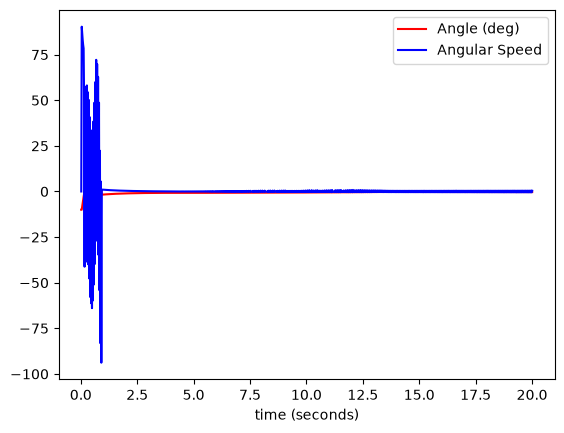

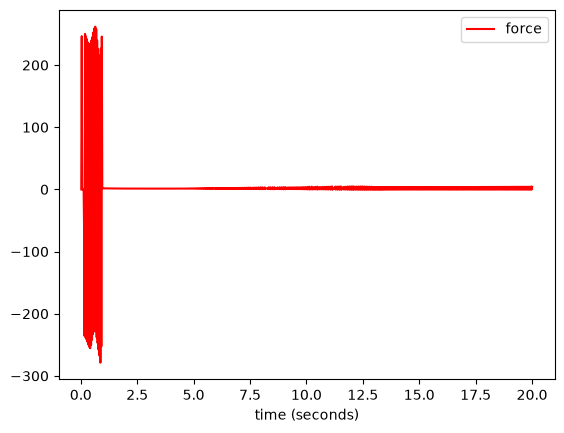

In [2]:
dpp = ar.data.DataPlotter()
dpp.set_x("time (seconds)")
dpp.add_y("force", "force")

dpa = ar.data.DataPlotter()
dpa.set_x("time (seconds)")
dpa.add_y("angle", "Angle (deg)")
dpa.add_y("speed", "Angular Speed")


# cart mass = 10 kg
# pendulum mass = 0.5 kg
# pendulum length = 0.5 m
pendulum = ar.system.InvertedPendulum(5.0, 0.5, 0.9, .5)
pendulum.set_angle(-math.radians(10))
#fuzzy_ctrl.engine.plot = True

dds = ar.dds.DDS()
dds.start()

dds.subscribe(['start'])
dds.wait('start')

t = ar.utils.Time()#use_fake_time = True)
t.start()
force = 0
while t.get() < 20:

    t.sleep(0.02)
    delta_t = t.elapsed()

    (p, v, angle, omega) = pendulum.get_status()
    
    dds.publish('position', p, ar.dds.DDS_TYPE_FLOAT)
    dds.publish('angle', angle, ar.dds.DDS_TYPE_FLOAT)

    dpp.append_x(t.get())
    dpp.append_y("force", force)
    
    dpa.append_x(t.get())
    dpa.append_y("angle", math.degrees(angle))
    dpa.append_y("speed", math.degrees(omega))
    
    force = fuzzy_ctrl.evaluate(angle, omega)
    pendulum.evaluate(delta_t, force)
    #print("Result = ", force)
    #print("-----------------")
    #print(angle, omega, force)
    
dpa.plot()
dpp.plot()

